# 03 — K-Means (user segmentation)

Clusters from engagement features; `k` chosen via silhouette.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

from corevent_analytics.config import get_settings
from corevent_analytics.data import load_data, build_user_features
from corevent_analytics.models import run_kmeans

sns.set_theme(style="whitegrid")
settings = get_settings()
tables, source = load_data(settings)
features = build_user_features(tables)
result = run_kmeans(
    features,
    k_max=settings.kmeans_k_max,
    random_state=settings.random_state,
)
print("source:", source)
result["metrics"]

source: synthetic


{'n_clusters': 2,
 'inertia': 56195.597302316564,
 'silhouette': 0.15769568262693745}

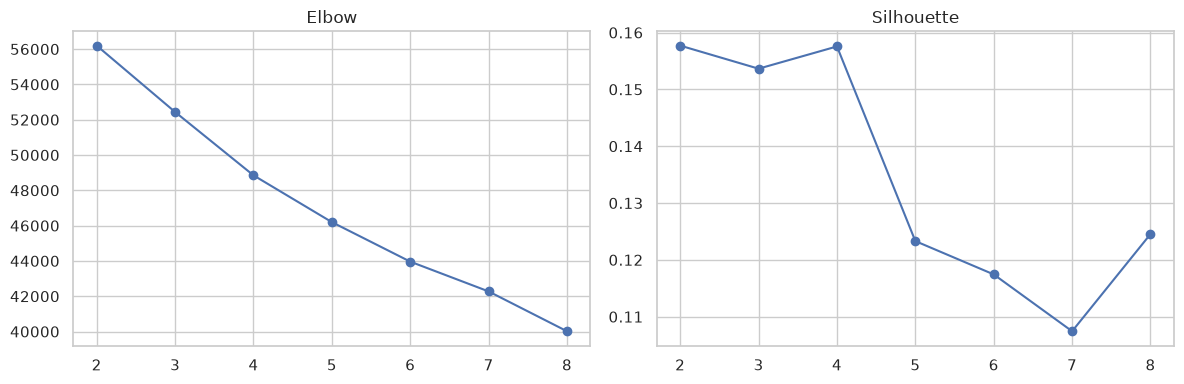

,age,account_age_days,n_orders,total_spent,avg_ticket,n_favorites,n_tickets,checkin_rate,cat_music,cat_sports,...,cat_education,cat_art_culture,cat_gastronomy,cat_health_wellness,cat_family_kids,cat_religious_spiritual,cat_games,cat_community_social,cat_fashion_beauty,cat_other
cluster,,,,,,,,,,,,,,,,,,,,,
0,40.576362,773.265103,0.201173,22.838710,19.665689,2.278592,0.320235,0.098143,0.199413,0.118475,...,0.231672,0.206452,0.231672,0.119062,0.126686,0.122581,0.103812,0.220528,0.112023,0.013490
1,41.371099,767.461776,2.796139,809.142857,307.922394,2.745174,5.653282,0.718068,0.294208,0.179151,...,0.318919,0.284942,0.314286,0.173745,0.179151,0.166023,0.162934,0.303475,0.146718,0.013127


In [2]:
selection = result["selection"]
if selection:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(selection["ks"], selection["inertias"], marker="o")
    axes[0].set_title("Elbow")
    axes[1].plot(selection["ks"], selection["silhouettes"], marker="o")
    axes[1].set_title("Silhouette")
    fig.tight_layout()
    plt.show()
result["centroids"]

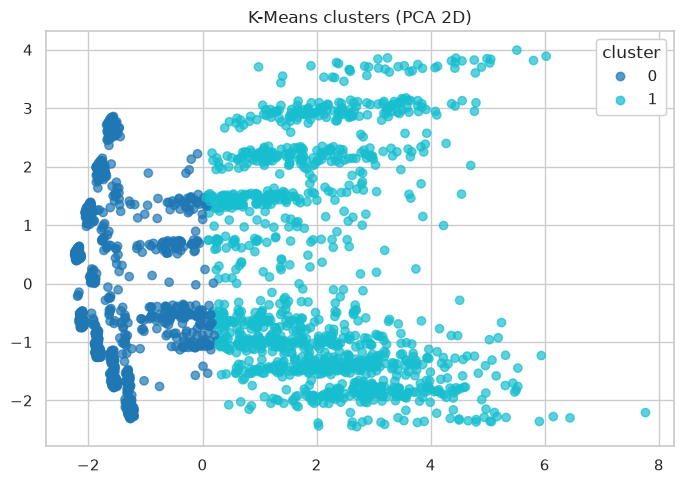

In [3]:
scaled = result.get("scaled_features")
labels = result.get("labels")
if scaled is not None and labels is not None and len(labels):
    pca = PCA(n_components=2, random_state=settings.random_state)
    xy = pca.fit_transform(scaled)
    fig, ax = plt.subplots(figsize=(7, 5))
    scatter = ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab10", alpha=0.7)
    ax.set_title("K-Means clusters (PCA 2D)")
    legend = ax.legend(*scatter.legend_elements(), title="cluster")
    ax.add_artist(legend)
    fig.tight_layout()
    plt.show()
else:
    print("Not enough data for PCA plot")